# Flächenanteile im Agentur↔NUTS-3-Crosswalk

Analyse der Verteilung von `area_share_of_agentur` / `area_share_of_nuts3`
in `transformed_data.mart_agentur_nuts3_crosswalk`
([mart_agentur_nuts3_crosswalk.sql](../pipeline/dbt/socioeconomic_data_pipeline/models/marts/mart_agentur_nuts3_crosswalk.sql)).

Hintergrund: Agenturbezirke bestehen i.d.R. aus einem oder mehreren ganzen
Kreisen (Ausnahme Berlin: 3 Agenturbezirke teilen sich einen Kreis). Die
Grenzlinien der BA-Agenturbezirk-Shapefile und der NUTS-3/GISCO-Shapefile
sind aber unabhängig digitalisiert und daher nie exakt deckungsgleich -
das erzeugt neben den echten Kreis-Anteilen auch winzige geometrische
"Krümel" entlang gemeinsamer Grenzen zu Nachbarkreisen, die keine echte
Zugehörigkeit darstellen. Das dbt-Modell filtert solche Krümel über einen
Schwellwert heraus (ursprünglich 0.2%, dann 0.5%, aktuell **10%** - siehe Fazit). Dieses Notebook visualisiert die
Verteilung der Anteile, um einen sinnvollen Schwellwert zu bestimmen.

Voraussetzung: das Mart muss **ohne Filter** gebaut sein, sonst fehlen die Krümel
(`dbt run --select mart_agentur_nuts3_crosswalk --vars '{crosswalk_min_share: 0}'`);
auf 10% gefiltert enthält es nur noch die echten Bestandteile. Außerdem: lokale Postgres/PostGIS-DB mit bereits gebautem
`mart_agentur_nuts3_crosswalk` (`dbt run --select mart_agentur_nuts3_crosswalk`),
z.B. über `docker compose -f compose.local.yml up` (siehe
[compose.local.yml](../compose.local.yml)). Verbindungsdaten können per
`PGHOST`/`PGPORT`/`PGDATABASE`/`PGUSER`/`PGPASSWORD` überschrieben werden.

In [1]:
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psycopg2

warnings.filterwarnings("ignore", message="pandas only supports SQLAlchemy connectable")

PGHOST = os.environ.get("PGHOST", "localhost")
PGPORT = int(os.environ.get("PGPORT", "5432"))
PGDATABASE = os.environ.get("PGDATABASE", "soziooekonomische-daten")
PGUSER = os.environ.get("PGUSER", "sozio_data_compose_user")
PGPASSWORD = os.environ.get("PGPASSWORD", "local_dev_password")

conn = psycopg2.connect(
    host=PGHOST, port=PGPORT, dbname=PGDATABASE, user=PGUSER, password=PGPASSWORD
)
df = pd.read_sql(
    """
    select cw.*, a.name as agentur_name
    from transformed_data.mart_agentur_nuts3_crosswalk cw
    join transformed_data.mart_agenturbezirk_sociodata a using (ba_schl)
    """,
    conn,
).drop_duplicates(subset=["ba_schl", "nuts_id"])
conn.close()
print(f"{len(df)} Zeilen, {df.ba_schl.nunique()} Agenturbezirke, {df.nuts_id.nunique()} NUTS-3-Regionen betroffen")
df.head()

764 Zeilen, 146 Agenturbezirke, 400 NUTS-3-Regionen betroffen


,ba_schl,nuts_id,region_name,intersection_area_m2,agentur_area_m2,nuts3_area_m2,area_share_of_agentur,area_share_of_nuts3,lau_population,agentur_total_population,nuts3_total_population,population_share_of_agentur,population_share_of_nuts3,agentur_name
0,030,DE80N,Vorpommern-Greifswald,3.767829e+09,3.794975e+09,3.793439e+09,0.992847,0.993249,None,None,None,None,None,Greifswald
236,031,DE80J,Mecklenburgische Seenplatte,5.479720e+09,5.494292e+09,5.497797e+09,0.997348,0.996712,None,None,None,None,None,Neubrandenburg
472,032,DE80K,Landkreis Rostock,3.414395e+09,3.599632e+09,3.429253e+09,0.948540,0.995667,None,None,None,None,None,Rostock
708,032,DE803,"Rostock, Kreisfreie Stadt",1.687824e+08,3.599632e+09,1.705693e+08,0.046889,0.989524,None,None,None,None,None,Rostock
944,033,DEF03,"Lübeck, Kreisfreie Stadt",1.428994e+06,7.021654e+09,2.111469e+08,0.000204,0.006768,None,None,None,None,None,Schwerin


## Verteilung (log-Skala)

Zwei Cluster sind zu erwarten: echte Kreis-Anteile (hohe Werte, oft nahe
100% auf mindestens einer der beiden Seiten) und geometrische Krümel
(sehr kleine Werte nahe 0). Gestrichelte Linien markieren
Schwellwert-Kandidaten.

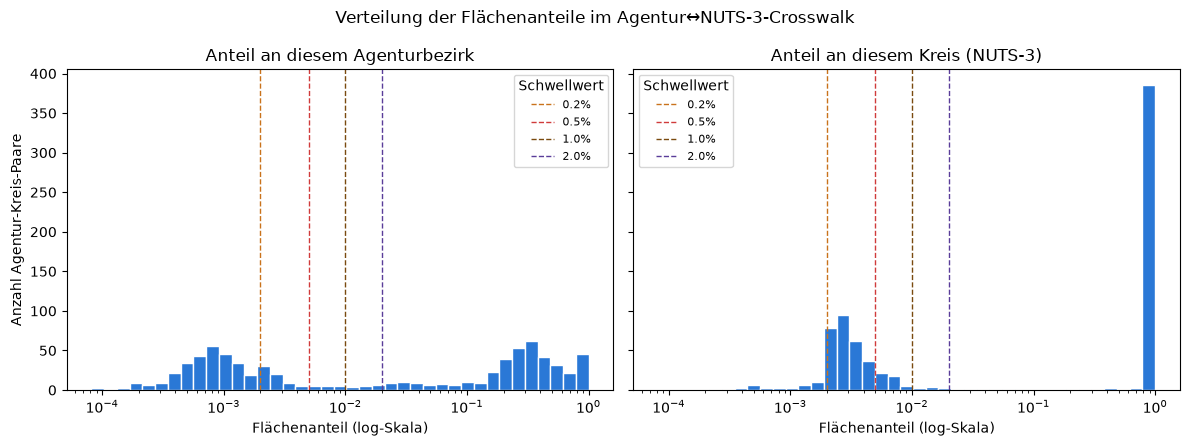

In [2]:
THRESHOLD_CANDIDATES = [0.002, 0.005, 0.01, 0.02]
THRESHOLD_COLORS = ["#c9721b", "#d03b3b", "#7a4a0f", "#5a3d99"]

share_cols = ["area_share_of_agentur", "area_share_of_nuts3"]
titles = ["Anteil an diesem Agenturbezirk", "Anteil an diesem Kreis (NUTS-3)"]

min_nonzero = df[share_cols].replace(0, np.nan).min().min()
bins = np.logspace(np.log10(min_nonzero), 0, 40)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, col, title in zip(axes, share_cols, titles):
    ax.hist(df[col].clip(lower=min_nonzero), bins=bins, color="#2a78d6", edgecolor="white")
    ax.set_xscale("log")
    ax.set_title(title)
    ax.set_xlabel("Flächenanteil (log-Skala)")
    for t, color in zip(THRESHOLD_CANDIDATES, THRESHOLD_COLORS):
        ax.axvline(t, color=color, linestyle="--", linewidth=1, label=f"{t:.1%}")
    ax.legend(fontsize=8, title="Schwellwert")

axes[0].set_ylabel("Anzahl Agentur-Kreis-Paare")
fig.suptitle("Verteilung der Flächenanteile im Agentur\u2194NUTS-3-Crosswalk")
fig.tight_layout()
plt.show()

## Zusammenhang beider Anteile

Jeder Punkt ist ein Agentur-Kreis-Paar. Echte Bestandteile liegen weit
oben rechts (mind. eine Seite hoch), Krümel unten links (beide Seiten
klein) - die Lücke dazwischen zeigt, wo ein Schwellwert die beiden
Gruppen sauber trennt.

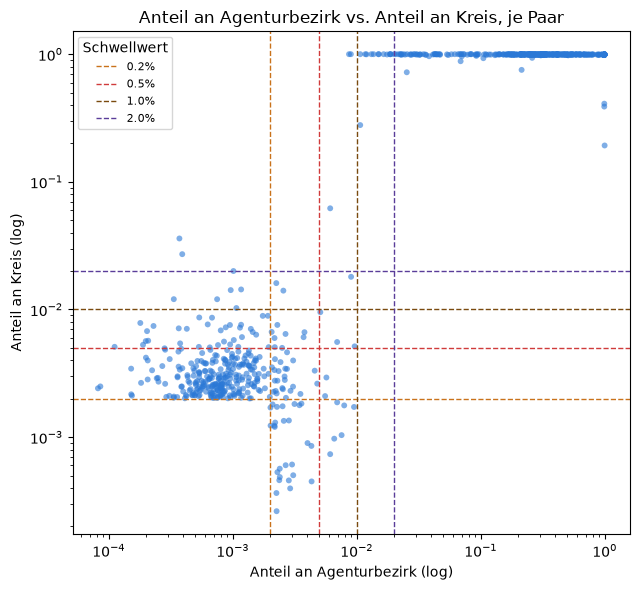

In [3]:
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(
    df["area_share_of_agentur"].clip(lower=min_nonzero),
    df["area_share_of_nuts3"].clip(lower=min_nonzero),
    s=18, alpha=0.6, color="#2a78d6", edgecolor="none",
)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Anteil an Agenturbezirk (log)")
ax.set_ylabel("Anteil an Kreis (log)")
ax.set_title("Anteil an Agenturbezirk vs. Anteil an Kreis, je Paar")
for t, color in zip(THRESHOLD_CANDIDATES, THRESHOLD_COLORS):
    ax.axvline(t, color=color, linestyle="--", linewidth=1)
    ax.axhline(t, color=color, linestyle="--", linewidth=1, label=f"{t:.1%}")
ax.legend(fontsize=8, title="Schwellwert")
fig.tight_layout()
plt.show()

## Sensitivität: wie viele Zeilen fallen bei welchem Schwellwert weg?

Ein Paar bleibt erhalten, wenn *mindestens einer* der beiden Anteile über
dem Schwellwert liegt (dieselbe ODER-Logik wie im dbt-Modell). Wichtige
Kontrolle: kein Agenturbezirk darf dabei komplett ohne NUTS-3-Zuordnung
zurückbleiben.

In [4]:
total_agenturbezirke = df.ba_schl.nunique()
rows = []
for t in [0.0, *THRESHOLD_CANDIDATES, 0.03, 0.05]:
    keep = (df.area_share_of_agentur > t) | (df.area_share_of_nuts3 > t)
    rows.append({
        "schwellwert": f"{t:.1%}",
        "zeilen_behalten": int(keep.sum()),
        "zeilen_verworfen": int((~keep).sum()),
        "agenturbezirke_ohne_zuordnung": total_agenturbezirke - df.loc[keep, "ba_schl"].nunique(),
    })
summary = pd.DataFrame(rows)
summary

,schwellwert,zeilen_behalten,zeilen_verworfen,agenturbezirke_ohne_zuordnung
0,0.0%,764,0,0
1,0.2%,764,0,0
2,0.5%,466,298,0
3,1.0%,415,349,0
4,2.0%,407,357,0
5,3.0%,405,359,0
6,5.0%,404,360,0


## Welche Zeilen fallen bei einem 1%-Schwellwert weg?

Alle 764 Zeilen, bei denen *beide* Anteile höchstens 1% betragen (würden
also verworfen, sobald der Schwellwert im dbt-Modell über 1% angehoben
wird) - absteigend nach dem jeweils größeren der beiden Anteile sortiert,
damit die "knappsten" Fälle (am ehesten noch ein echter, aber sehr kleiner
Kreis-Anteil) oben stehen.

In [5]:
dropped_at_1pct = df[(df.area_share_of_agentur <= 0.01) & (df.area_share_of_nuts3 <= 0.01)].copy()
dropped_at_1pct["max_share"] = dropped_at_1pct[["area_share_of_agentur", "area_share_of_nuts3"]].max(axis=1)
dropped_at_1pct = dropped_at_1pct.sort_values("max_share", ascending=False)
print(f"{len(dropped_at_1pct)} von {len(df)} Zeilen würden bei einem 1%-Schwellwert verworfen")
dropped_at_1pct[[
    "ba_schl", "agentur_name", "nuts_id", "region_name",
    "area_share_of_agentur", "area_share_of_nuts3",
]].reset_index(drop=True)

349 von 764 Zeilen würden bei einem 1%-Schwellwert verworfen


,ba_schl,agentur_name,nuts_id,region_name,area_share_of_agentur,area_share_of_nuts3
0,337,Düsseldorf,DEA1C,Mettmann,0.009610,0.005145
1,364,Mettmann,DEA11,"Düsseldorf, Kreisfreie Stadt",0.005081,0.009528
2,075,Leipzig,DED52,Leipzig,0.009500,0.001724
3,433,Bad Homburg,DE712,"Frankfurt am Main, Kreisfreie Stadt",0.001919,0.008923
4,357,Köln,DEA24,"Leverkusen, Kreisfreie Stadt",0.001745,0.008914
...,...,...,...,...,...,...
344,611,Aalen,DE11A,Schwäbisch Hall,0.001400,0.002018
345,139,Neumünster,DEF0E,Steinburg,0.000915,0.002015
346,827,Ingolstadt,DE217,Dachau,0.000410,0.002015
347,621,Göppingen,DE11D,Ostalbkreis,0.002013,0.001705


## Sonderfall Berlin: ab wann bleibt nur noch Kreis Berlin?

Berlin ist eine einzige NUTS-3-Region (`DE300`), aufgeteilt auf drei
Agenturbezirke (Nord/Mitte/Süd) - der Ausnahmefall aus der Modell-
Beschreibung, bei dem *mehrere* Agenturbezirke sich *einen* Kreis teilen,
statt umgekehrt. Zusätzlich zu Berlin selbst grenzen alle drei
Agenturbezirke an brandenburgische Nachbarkreise, wodurch dieselben
geometrischen Krümel entstehen wie überall sonst.

In [6]:
berlin = df[df.agentur_name.str.contains("erlin", case=False, na=False)].copy()
berlin["max_share"] = berlin[["area_share_of_agentur", "area_share_of_nuts3"]].max(axis=1)
berlin = berlin.sort_values(["ba_schl", "max_share"], ascending=[True, False])
berlin[[
    "ba_schl", "agentur_name", "nuts_id", "region_name",
    "area_share_of_agentur", "area_share_of_nuts3", "max_share",
]].reset_index(drop=True)

,ba_schl,agentur_name,nuts_id,region_name,area_share_of_agentur,area_share_of_nuts3,max_share
0,922,Berlin Süd,DE300,Berlin,0.990610,0.409555,0.990610
1,922,Berlin Süd,DE40C,Oder-Spree,0.003073,0.000503,0.003073
2,922,Berlin Süd,DE406,Dahme-Spreewald,0.002249,0.000365,0.002249
3,922,Berlin Süd,DE404,"Potsdam, Kreisfreie Stadt",0.001126,0.002213,0.002213
4,955,Berlin Nord,DE300,Berlin,0.990041,0.388660,0.990041
5,955,Berlin Nord,DE404,"Potsdam, Kreisfreie Stadt",0.002189,0.004084,0.004084
6,955,Berlin Nord,DE408,Havelland,0.003007,0.000610,0.003007
7,955,Berlin Nord,DE405,Barnim,0.002392,0.000566,0.002392
8,955,Berlin Nord,DE40A,Oberhavel,0.002372,0.000460,0.002372
9,962,Berlin Mitte,DE300,Berlin,0.996635,0.192675,0.996635


In [7]:
# Für jeden Berlin-Agenturbezirk: größter Anteil unter den NICHT-Berlin-Zeilen.
# Der Schwellwert muss diesen Wert übersteigen, damit nur noch DE300 übrig bleibt.
non_berlin = berlin[berlin.nuts_id != "DE300"]
needed_threshold = non_berlin.groupby("agentur_name")["max_share"].max().rename("groesster_nicht_berlin_anteil")
berlin_de300 = berlin[berlin.nuts_id == "DE300"].set_index("agentur_name")[
    ["area_share_of_agentur", "area_share_of_nuts3"]
].rename(columns={
    "area_share_of_agentur": "anteil_berlin_an_agentur",
    "area_share_of_nuts3": "anteil_dieses_agentur_an_berlin",
})
summary_berlin = berlin_de300.join(needed_threshold)
summary_berlin

,anteil_berlin_an_agentur,anteil_dieses_agentur_an_berlin,groesster_nicht_berlin_anteil
agentur_name,,,
Berlin Süd,0.990610,0.409555,0.003073
Berlin Nord,0.990041,0.388660,0.004084
Berlin Mitte,0.996635,0.192675,0.002256


**Ergebnis:** In jedem der drei Berlin-Agenturbezirke macht `DE300` schon
heute >99% der Agentur-Fläche aus; die übrigen Zeilen sind ausschließlich
Krümel Richtung Brandenburg (Oder-Spree, Dahme-Spreewald,
Potsdam/Havelland/Barnim/Oberhavel), keine echten Bestandteile. Der
größte dieser Krümel liegt bei rund 0.4% (Berlin Nord → Potsdam,
Kreisfreie Stadt). Ab einem Schwellwert von etwas über diesem Wert (die
bereits empfohlenen **0.5%** reichen dafür aus) bliebe für alle drei
Berlin-Agenturbezirke nur noch die Zeile `DE300` übrig.

Wichtig: Die drei Agenturbezirke würden dabei **nicht** ununterscheidbar
"100% Berlin" - `anteil_dieses_agentur_an_berlin` (`area_share_of_nuts3`)
bleibt unterschiedlich (~19% / 39% / 41%, in Summe ~99% von Berlins
Gesamtfläche) und zeigt weiterhin korrekt, welcher Teil Berlins auf
welchen Agenturbezirk entfällt. Nur die nicht-repräsentativen
Brandenburg-Krümel verschwinden - der eigentliche Berlin-Sonderfall
(3 Agenturbezirke teilen sich einen Kreis) bleibt vollständig abgebildet.

## Fazit

Die Verteilung ist klar zweigeteilt, mit einer fast leeren Lücke dazwischen:
der jeweils größere der beiden Anteile liegt bei ca. 98% aller Paare entweder
unter 1% (Krümel) oder über 20% (echte Bestandteile) - nur eine Handvoll
Paare (12 von 764) liegen dazwischen. Ein Schwellwert zwischen **0.5% und 1%**
liegt sicher in dieser Lücke: er entfernt zuverlässig die geometrischen
Krümel, ohne echte (auch kleinere) Kreis-Anteile zu verlieren, und kein
Agenturbezirk verliert dabei seine NUTS-3-Zuordnung komplett (siehe Tabelle
oben, Spalte `agenturbezirke_ohne_zuordnung` bleibt 0). Aktuell steht der
Schwellwert in
[mart_agentur_nuts3_crosswalk.sql](../pipeline/dbt/socioeconomic_data_pipeline/models/marts/mart_agentur_nuts3_crosswalk.sql)
bei 0.2% - das lässt die 298 Krümel-Paare aus der 0.2-0.5%-Zone
(siehe Sensitivitäts-Tabelle) noch durch.

Der Berlin-Sonderfall bestätigt das: der größte Nicht-Berlin-Krümel dort liegt bei ca. 0.41% (Berlin Nord → Potsdam), 0.5% reicht also auch hier sicher aus, ohne die drei unterschiedlichen Berlin-Anteile (siehe Abschnitt oben) zu verlieren.

**Nachtrag (Schwelle 0.5% → 10%):** Im Frontend tauchte unter "Teilweise überlappende
Agenturbezirke" für Stuttgart der Agenturbezirk Ludwigsburg (BA 641) mit "0 %" auf. Ursache
war kein Rechenfehler, sondern ein Krümel von 1.4 km² (0.2% des Agenturbezirks, aber 0.67% des
kleinen Stadtkreises Stuttgart) - er blieb wegen der ODER-Logik über `area_share_of_nuts3`
oberhalb von 0.5% hängen. Bei kleinen Kreisfreien Städten macht ein Krümel schnell mehrere %
der Kreisfläche aus; die obige Aussage "Krümel < 1%" gilt daher nur für den *größeren* Anteil
großer Kreise. Tatsächlich liegen alle 63 Paare mit einem größeren Anteil zwischen 0.5% und 25%
bei höchstens 6.2% (Krümel), echte Bestandteile beginnen erst bei ~27.8%. Schwelle deshalb
auf **10%** (mitten in der Lücke) angehoben: alle 146 Agenturbezirke und alle 400 betroffenen
NUTS-3-Regionen behalten mindestens eine Zeile, es bleiben 403 statt 466 Zeilen. Die
Ausgaben der Zellen oben stammen noch vom ungefilterten Stand.
